# Financial Analyst Agent for Annual Report Writing

In this demo, we introduce an agent that can analyze financial report.

In [1]:
import os
import autogen
from textwrap import dedent
from finrobot.utils import register_keys_from_json
from finrobot.agents.workflow import SingleAssistantShadow

c:\Users\franc\dev\FinRobot\.venv\Lib\site-packages\flaml\__init__.py:20: UserWarning: flaml.automl is not available. Please install flaml[automl] to enable AutoML functionalities.
  warnings.warn("flaml.automl is not available. Please install flaml[automl] to enable AutoML functionalities.")


After importing all the necessary packages and functions, we also need the config for OpenAI & SecApi & FMPApi here. 
- for openai configuration, rename OAI_CONFIG_LIST_sample to OAI_CONFIG_LIST and replace the api keys
- for Sec_api & FMP_api configuration, rename config_api_keys_sample to config_api_keys and replace the api keys

In [2]:
llm_config = {
    "config_list": autogen.config_list_from_json(
        "../OAI_CONFIG_LIST",
        filter_dict={"model": ["anthropic/claude-haiku-5.5"]},
    ),
    "timeout": 300,
    "temperature": 0.5,
    "parallel_tool_calls": False,
    "max_tokens": 16000,
    "extra_body": {"reasoning": {"effort": "low"}},
}
register_keys_from_json("../config_api_keys")

In [3]:
# Intermediate results will be saved in this directory
work_dir = "../report"
os.makedirs(work_dir, exist_ok=True)

assistant = SingleAssistantShadow(
    "Expert_Investor",
    llm_config,
    max_consecutive_auto_reply=30,
    human_input_mode="TERMINATE",
)

User_Proxy (to Expert_Investor):


With the tools you've been provided, write an annual report based on RKLB's 2025 10-k report, format it into a pdf.
Pay attention to the followings:
- Explicitly explain your working plan before you kick off.
- Use tools one by one for clarity, especially when asking for instructions. 
- All your file operations should be done in "../report".
- For the competitor analysis use these ticker symbols: LUNR, RDW, PL. 
- Display any image in the chat once generated.
- All the paragraphs should combine between 400 and 450 words, don't generate the pdf until this is explicitly fulfilled.


--------------------------------------------------------------------------------
Expert_Investor (to User_Proxy):

I'll start by explaining the working plan, then run the tools one at a time.

**Working plan**

1. **Locate the filing.** Get the FY2025 10-K for RKLB (Rocket Lab) and its filing date.
2. **Gather the analytical inputs, one tool at a time, saving files to `../r

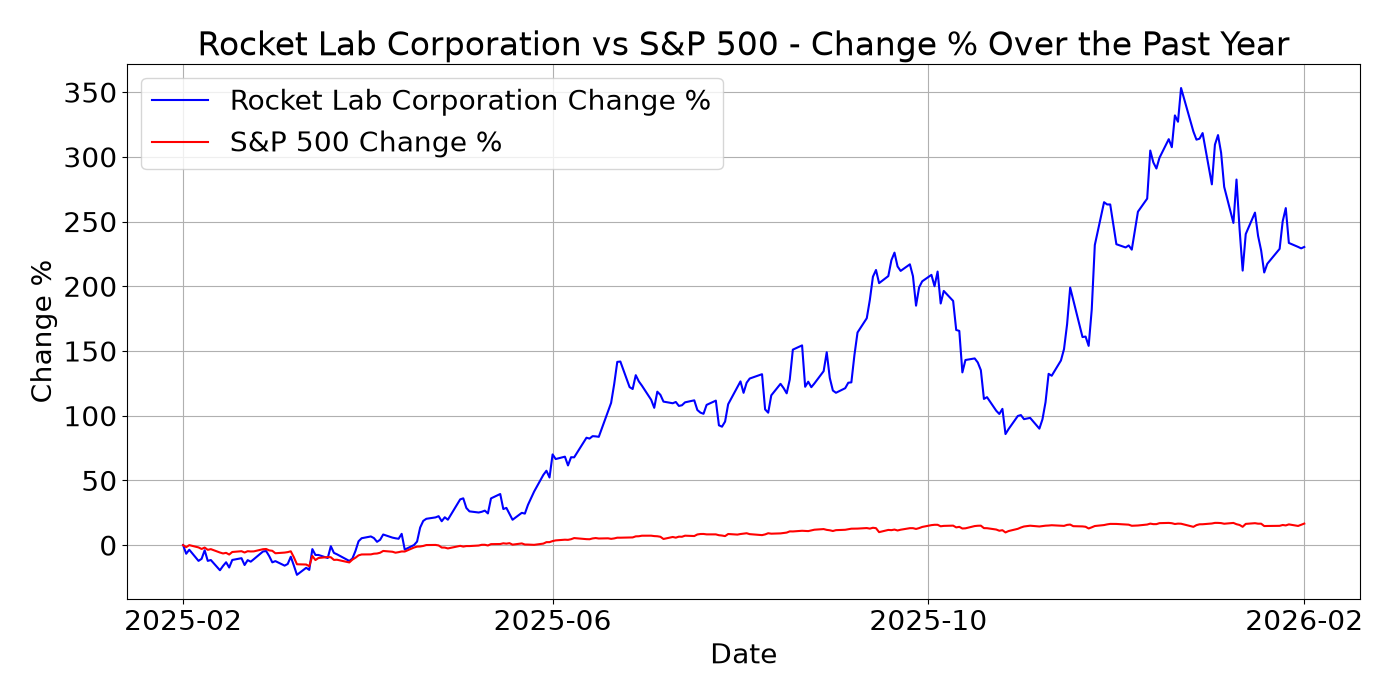

User_Proxy (to Expert_Investor):

User_Proxy (to Expert_Investor):

***** Response from calling tool (toolu_01KeJCsh8FpCbWkwA6Mxdr4t) *****
None
***********************************************************************

--------------------------------------------------------------------------------
[autogen.oai.client: 11-19 13:58:06] {329} WARNING - Model anthropic/claude-haiku-5.5 is not found. The cost will be 0. In your config_list, add field {"price" : [prompt_price_per_1k, completion_token_price_per_1k]} for customized pricing.
Expert_Investor (to User_Proxy):

The share performance chart is saved to `../report/rklb_share_performance.png` and displayed above. Next, I'll generate the PE and EPS chart.
***** Suggested tool call (toolu_016bLoVjDqJAcCrbYrsnDrkN): get_pe_eps_performance *****
Arguments: 
{"ticker_symbol": "RKLB", "filing_date": "2026-02-26", "save_path": "../report/rklb_pe_eps_performance.png"}
***************************************************************************

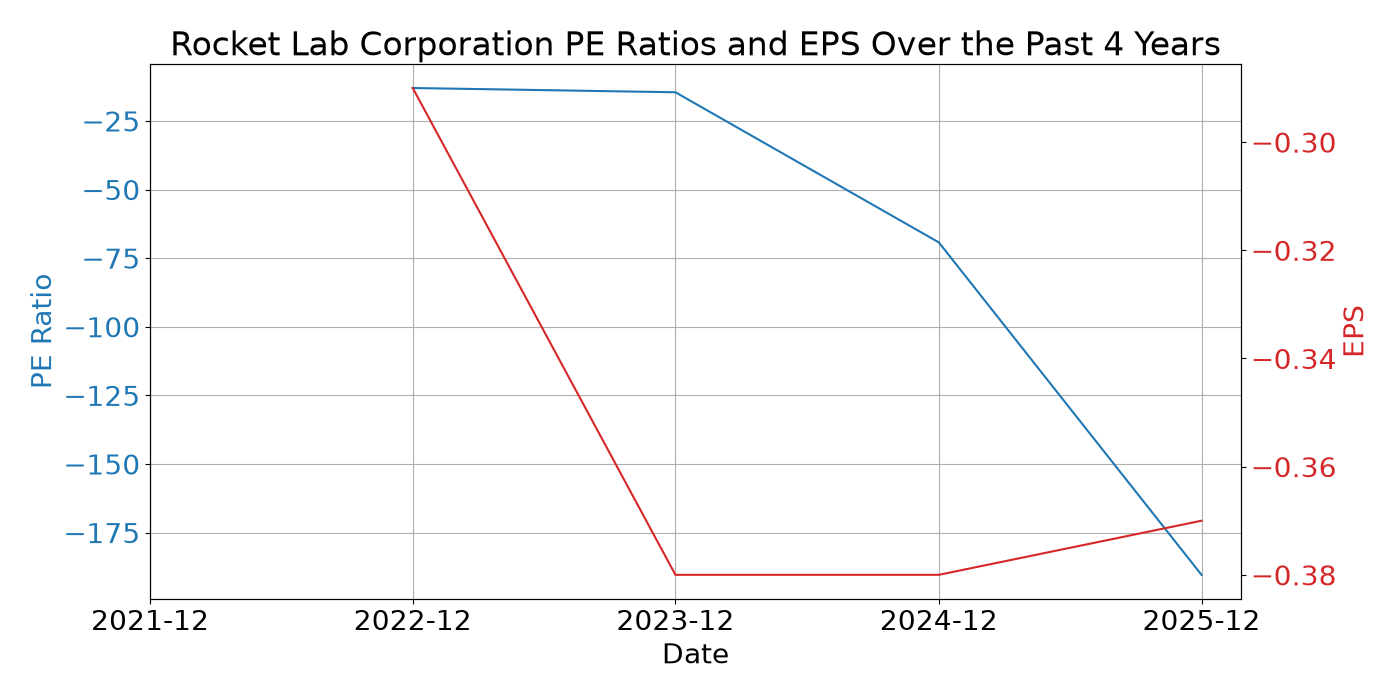

User_Proxy (to Expert_Investor):

User_Proxy (to Expert_Investor):

***** Response from calling tool (toolu_01Ey83PWGnAteHmNM9kGKxaA) *****
None
***********************************************************************

--------------------------------------------------------------------------------
[autogen.oai.client: 11-19 13:59:07] {329} WARNING - Model anthropic/claude-haiku-5.5 is not found. The cost will be 0. In your config_list, add field {"price" : [prompt_price_per_1k, completion_token_price_per_1k]} for customized pricing.
Expert_Investor (to User_Proxy):



--------------------------------------------------------------------------------

>>>>>>>> USING AUTO REPLY...
User_Proxy (to Expert_Investor):



--------------------------------------------------------------------------------


c:\Users\franc\dev\FinRobot\.venv\Lib\site-packages\autogen\agentchat\conversable_agent.py:1443: UserWarning: Extracted_response from ChatCompletion(id='gen-1795093088-dCqoCADuqHUTdxOEnux9', choices=[Choice(finish_reason='length', index=0, logprobs=None, message=ChatCompletionMessage(content=None, refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning="Both charts are finished and shown. Next I'll write the market position and business overview paragraphs, then check their word counts against the 400-450 target, since some drafts have run long. The check tool only measures characters, so I'll have to estimate words from that.\n\nNext I'll check the word counts on the market position and business overview paragraphs, which I'm drafting now, since some earlier drafts ran long. The length tool only counts characters, so I'll estimate words from that and count by hand where it matters.\n\nDrafting the business overview now, and the Elec

[autogen.oai.client: 11-19 13:59:35] {329} WARNING - Model anthropic/claude-haiku-5.5 is not found. The cost will be 0. In your config_list, add field {"price" : [prompt_price_per_1k, completion_token_price_per_1k]} for customized pricing.
Expert_Investor (to User_Proxy):

I've drafted the business overview and market position paragraphs. I counted each one by hand, so the counts are approximate. The other three sections still need work before the PDF can be built.

**Business Overview (about 411 words)**

Rocket Lab Corporation (RKLB), founded in 2006, is an end-to-end space company that designs, manufactures, and launches spacecraft and provides on-orbit management services. The company reports through two segments: Space Systems and Launch Services. Its Electron small launch vehicle, powered by 3D-printed Rutherford engines, has completed 77 successful missions as of February 26, 2026, and the company has delivered more than 200 spacecraft to orbit. The company's vertical integratio

In [ ]:
company = "RKLB"
fyear = "2025"

message = dedent(
    f"""
    - Explicitly explain your working plan before you kick off.
    - Use tools one by one for clarity, especially when asking for instructions.
    - All your file operations should be done in "{work_dir}".
    - Display any image in the chat once generated.
    - For the competitor analysis use these ticker symbols: LUNR, RDW, PL.
    - Each of the five sections should be roughly 350-450 words, split into 2-4 paragraphs.
    - Also write an investment summary of 150-300 words for page 1.
    - Cite sources inline as [1] 10-K, [2] Yahoo Finance financials/prices, [3] analyst consensus, [4] peer financials.
    - Do not generate the pdf until all of this is fulfilled.
"""
)

assistant.chat(message, use_cache=True, max_turns=50,
               summary_method="last_msg")

Zeige: ../report\rklb_annual_report.pdf


c:\Users\franc\dev\FinRobot\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


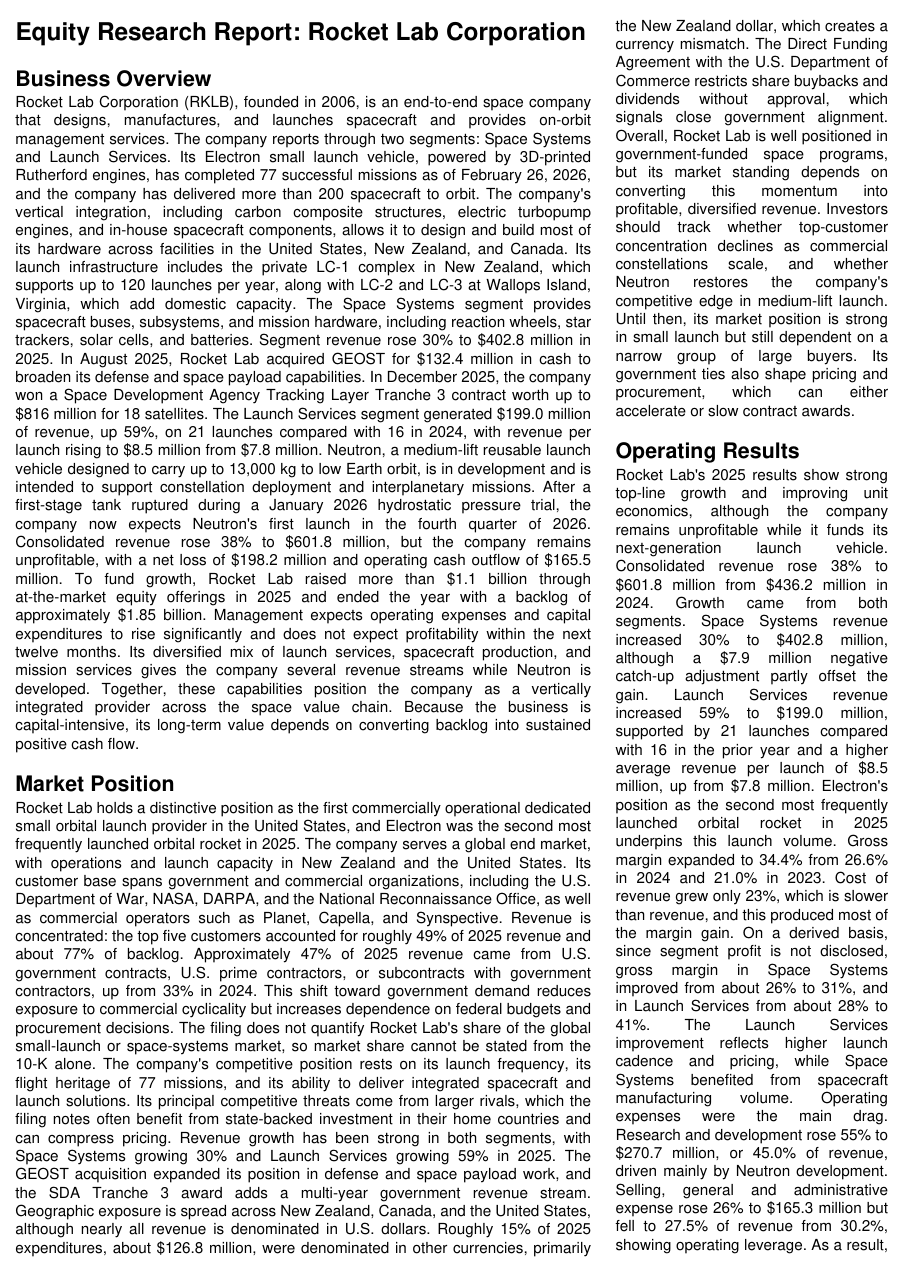

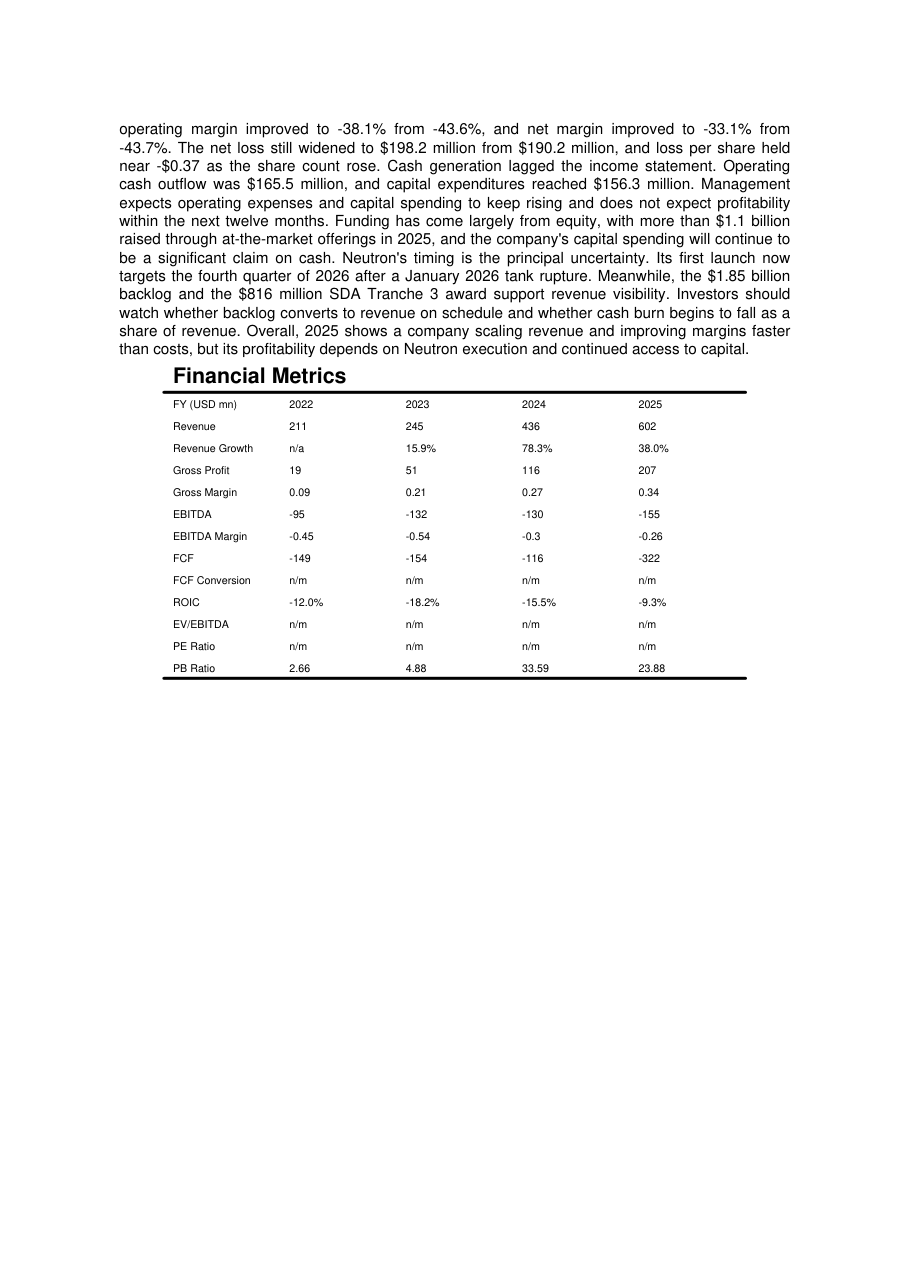

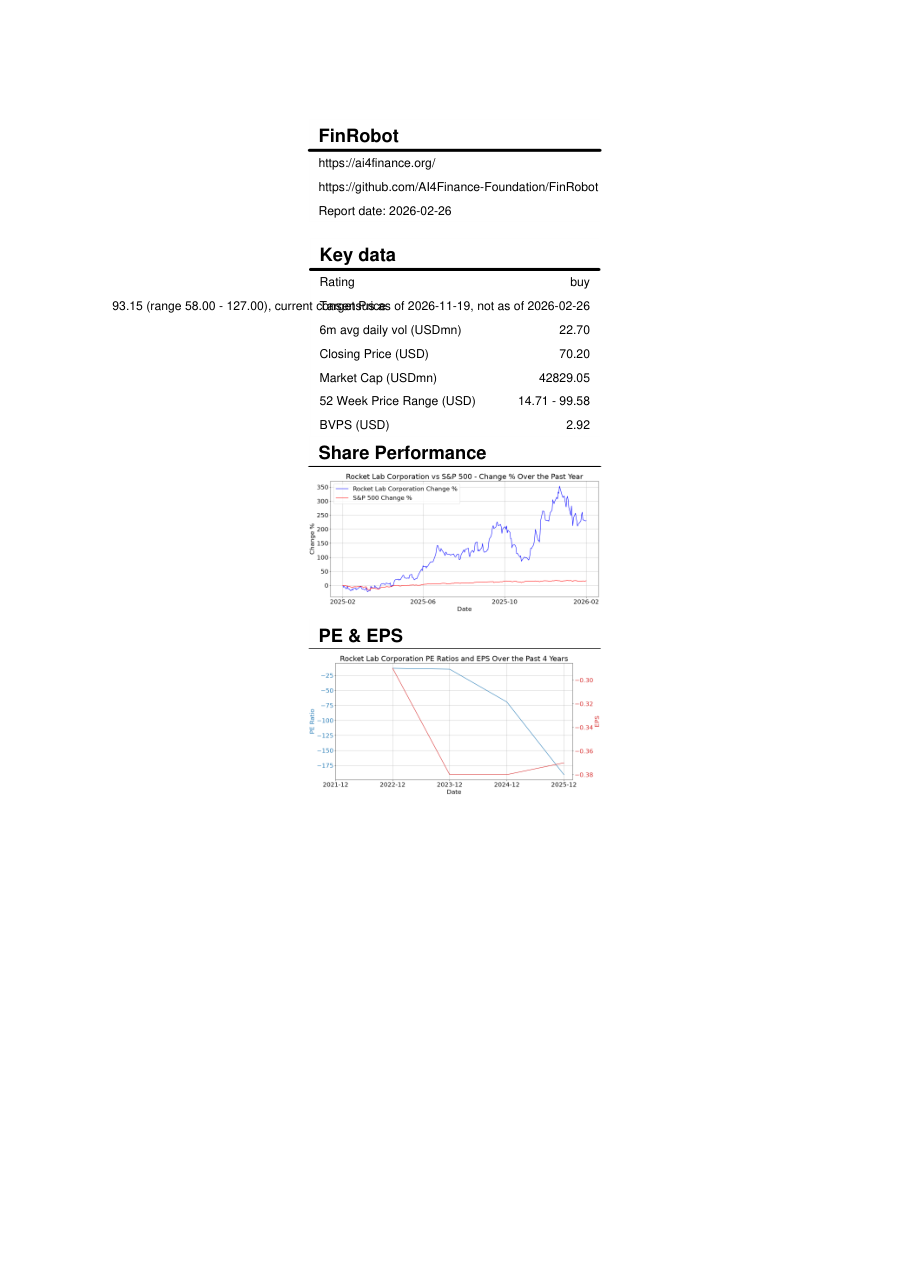

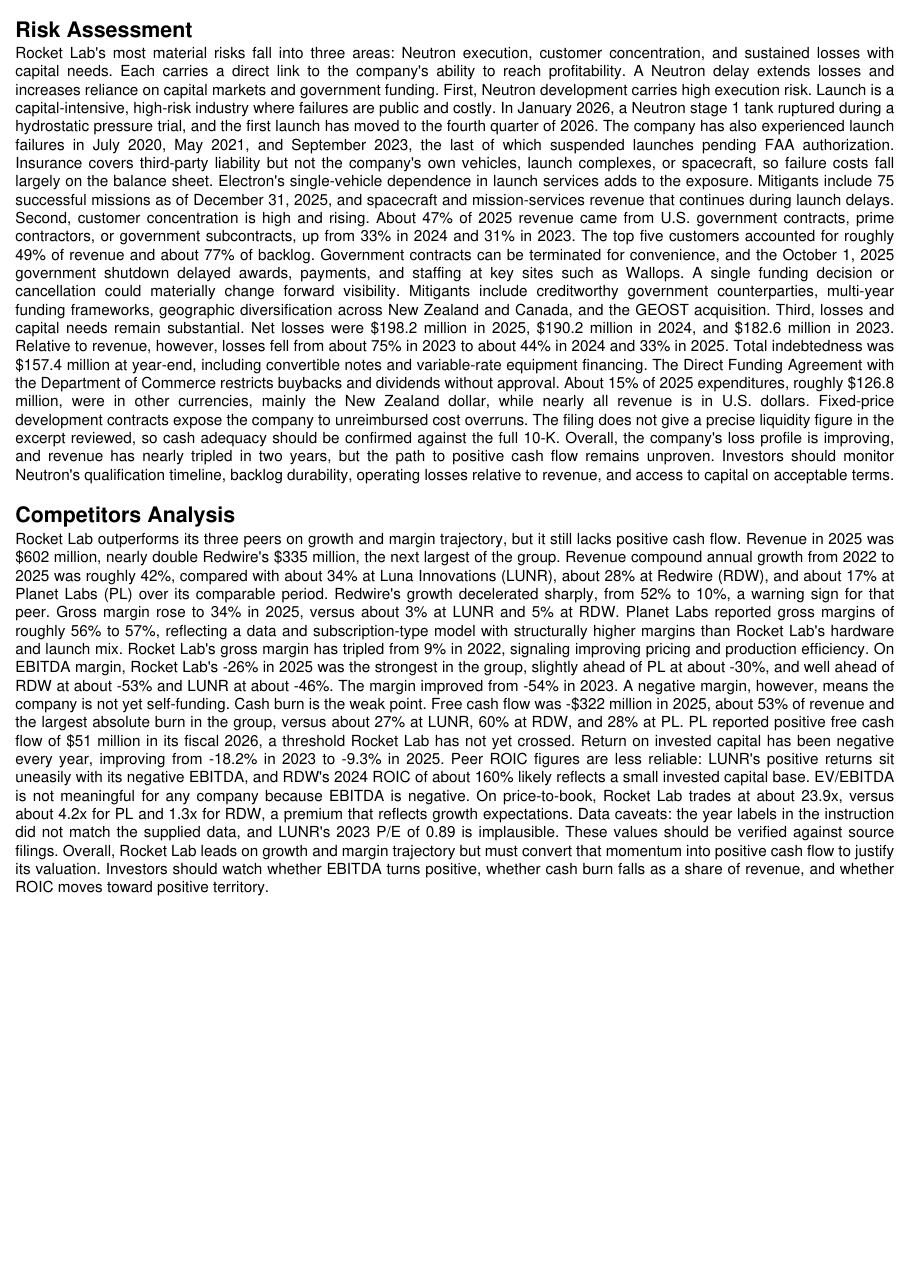

In [5]:
import io, glob, os
import fitz
from PIL import Image

pdfs = sorted(glob.glob("../report/*RKLB*.pdf"), key=os.path.getmtime)
if not pdfs:
    print("Kein PDF in ../report gefunden – der Agent hat keinen Report erzeugt.")
else:
    print("Zeige:", pdfs[-1])
    pdf = fitz.open(pdfs[-1])
    for page in pdf:
        img = Image.open(io.BytesIO(page.get_pixmap(dpi=110).tobytes("png")))
        display(img)